In [10]:
!pip install ultralytics

In [11]:
import cv2
import numpy as np
from ultralytics import YOLO

In [12]:
cap = cv2.VideoCapture("https://media.roboflow.com/supervision/video-examples/people-walking.mp4");


In [13]:
previous = {}


fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

heatmap = np.zeros((h,w), dtype=np.float32)

counted_in = set()
counted_out = set()

UPPER_LINE_Y = 300
LOWER_LINE_Y = 600

In [14]:
output_video="output.mp4"
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(
    output_video,
    fourcc,
    fps,
    (w, h)
)

In [15]:
model = YOLO("yolo11n.pt")

In [16]:
while True:
  ret, frame = cap.read()
  if not ret:
    break

  results = model.track(
      frame,
      persist=True,
      tracker="bytetrack.yaml",
      classes=[0]
  )

  boxes = results[0].boxes
  if boxes.id is not None:
    for box, track_id in zip(boxes, boxes.id):
      track_id = int(track_id)
      x1,y1,x2,y2 = box.xyxy[0].tolist()
      x1,y1,x2,y2 = int(x1),int(y1),int(x2),int(y2)
      cx = int((x1+x2)/2)
      cy = int((y1+y2)/2)

      heatmap[cy,cx] += 1

      if track_id in previous:
        previous_cx, previous_cy = previous[track_id]
        if (cy >= UPPER_LINE_Y and previous_cy < UPPER_LINE_Y ):
          counted_in.add(track_id)
        elif (cy <= LOWER_LINE_Y and previous_cy > LOWER_LINE_Y):
          counted_out.add(track_id)


  previous[track_id] = [cx,cy]

  annoted_frame = results[0].plot()

  cv2.line(
    annoted_frame,
    (0, UPPER_LINE_Y),
    (annoted_frame.shape[1], UPPER_LINE_Y),
    (0, 0, 255),
  )
  cv2.line(
    annoted_frame,
    (0, LOWER_LINE_Y),
    (annoted_frame.shape[1], LOWER_LINE_Y),
    (0, 0, 255),
  )
  cv2.rectangle(
    annoted_frame,
    (5, 5),
    (130, 45),
    (255, 255, 255),
    -1
  )
  cv2.putText(
    annoted_frame,
    f"In: {len(counted_in)}",
    (10, 30),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 0, 0),
    2,
  )
  cv2.rectangle(
    annoted_frame,
    (5, 50),
    (140, 90),
    (255, 255, 255),
    -1
  )
  cv2.putText(
    annoted_frame,
    f"Out: {len(counted_out)}",
    (10, 70),
     cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 0, 0),
    2,
  )
  out.write(annoted_frame)



cap.release()
out.release()


0: 384x640 17 persons, 20.3ms
Speed: 4.4ms preprocess, 20.3ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 17 persons, 27.5ms
Speed: 5.5ms preprocess, 27.5ms inference, 2.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 17 persons, 12.3ms
Speed: 4.2ms preprocess, 12.3ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 18 persons, 24.0ms
Speed: 5.4ms preprocess, 24.0ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 19 persons, 16.0ms
Speed: 3.4ms preprocess, 16.0ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 19 persons, 13.9ms
Speed: 3.7ms preprocess, 13.9ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 19 persons, 13.1ms
Speed: 3.7ms preprocess, 13.1ms inference, 2.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 19 persons, 40.2ms
Speed: 11.3ms preprocess, 40.2ms inference, 4.7ms postprocess per image a

In [17]:
heatmap = cv2.GaussianBlur(
    heatmap,
    (0,0),
    sigmaX=10,
    sigmaY=10,
)

heatmap_norm = cv2.normalize(
    heatmap,
    None,
    alpha=0,
    beta=255,
    norm_type=cv2.NORM_MINMAX,
)

heatmap_norm = heatmap_norm.astype(np.uint8)

heatmap_color = cv2.applyColorMap(
    heatmap_norm,
    cv2.COLORMAP_JET
)


In [18]:
cv2.imwrite("heatmap.png", heatmap_color)

True

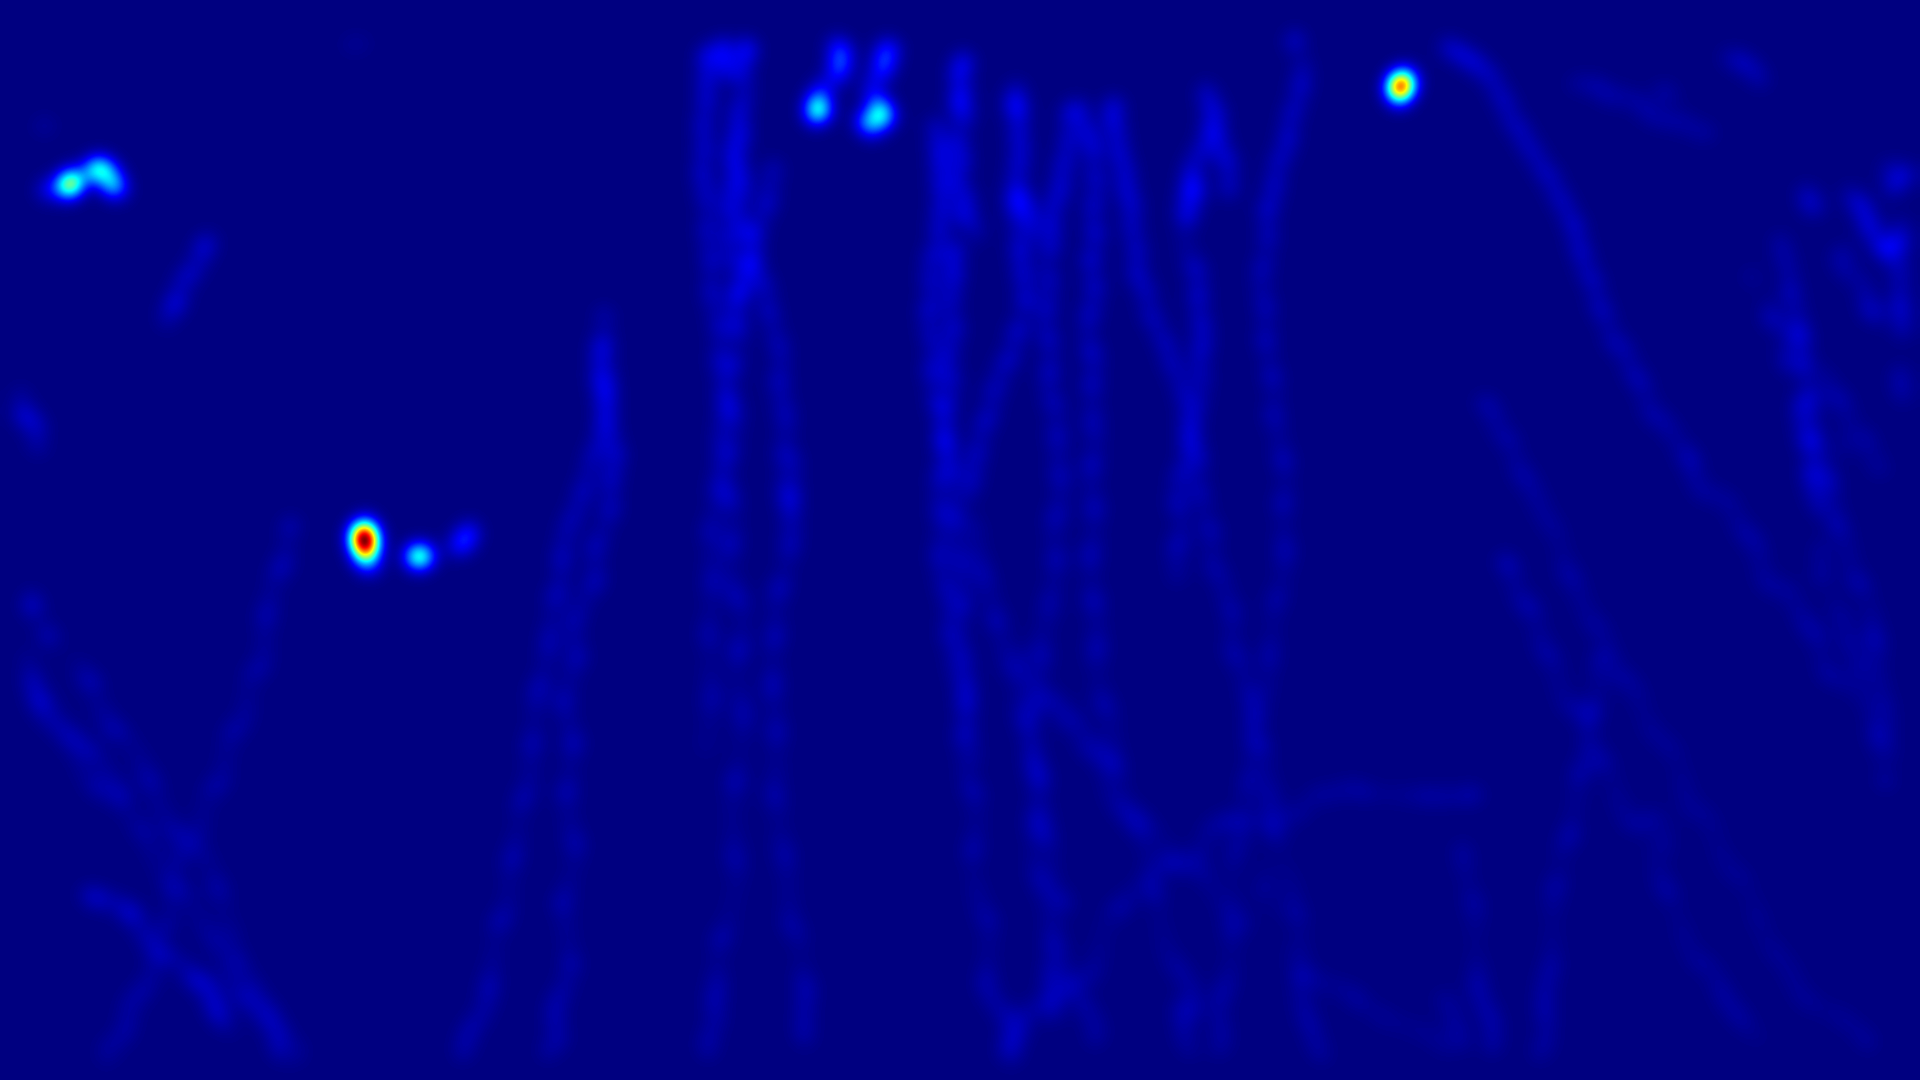

